# Stroop och flankertest, en jämförelse.

### Importera verktyg

In [3]:
#importerar in verktyg och bibliotek
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Flanker
läser in och konverterar vår excelfil

In [5]:
#läser in vår fil
df_flanker = pd.read_excel("Raw_Flanker.xlsx")

#spara som csv i samma directory
df_flanker.to_csv("Raw_Flanker.csv", index=False)

### Utforska och få en överblick över datan
Titta efter NaN, se vilka kolumner vi behöver och hur vi på andra sätt kan förenkla vår data till vårt syfte

In [7]:
#utforska datan

df_flanker = pd.read_csv("Raw_Flanker.csv")

print("Flanker info")
df_flanker.info()
display(df_flanker.head())


Flanker info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123084 entries, 0 to 123083
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   build                 123084 non-null  object
 1   computer.platform     123084 non-null  object
 2   date                  123084 non-null  int64 
 3   time                  123084 non-null  object
 4   values.practice       123084 non-null  int64 
 5   blockcode             123084 non-null  object
 6   blocknum              123084 non-null  int64 
 7   values.blockcount     123084 non-null  int64 
 8   trialcode             123084 non-null  object
 9   trialnum              123084 non-null  int64 
 10  values.trialcount     123084 non-null  int64 
 11  values.congruence     123084 non-null  int64 
 12  values.selecttarget   123084 non-null  int64 
 13  values.selectflanker  123084 non-null  int64 
 14  response              123084 non-null  int64 
 15  corr

,build,computer.platform,date,time,values.practice,blockcode,blocknum,values.blockcount,trialcode,trialnum,values.trialcount,values.congruence,values.selecttarget,values.selectflanker,response,correct,latency,subjectid
0,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetleft_congruent,2,1,1,2,2,16,1,867,1
1,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetright_congruent,4,2,1,1,1,25,1,416,1
2,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetright_incongruent,6,3,2,1,2,25,1,391,1
3,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetright_incongruent,8,4,2,1,2,25,1,467,1
4,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetright_congruent,10,5,1,1,1,25,1,389,1


In [8]:
#leta efter NaN

print("Tot NaN for Flanker-test")
df_flanker.isna().sum()

Tot NaN for Flanker-test


build                   0
computer.platform       0
date                    0
time                    0
values.practice         0
blockcode               0
blocknum                0
values.blockcount       0
trialcode               0
trialnum                0
values.trialcount       0
values.congruence       0
values.selecttarget     0
values.selectflanker    0
response                0
correct                 0
latency                 0
subjectid               0
dtype: int64

### Cleana vår data
Välja kolumner som vi vill ha kvar, sortera, skapa ny kolumn 'session', ta bort practiceruns, göra 'date' tydligare etc

In [10]:
# gör datumet mer lättläst
df_flanker['date'] = pd.to_datetime(df_flanker['date'].astype(str).str.zfill(6), format='%m%d%y', errors='coerce').dt.strftime('%Y-%m-%d')

In [11]:
# sortera kronologiskt efter deltagare, datum och tid så sessionerna hamnar i rätt ordning
df_flanker = df_flanker.sort_values(by=['subjectid', 'date', 'time'])

In [12]:
# skapa 'session'-kolumnen per deltagare (1 = tidigaste tillfället, 2 = nästa, 3 = sista)
df_flanker['session'] = df_flanker.groupby('subjectid')['date'].transform(lambda x: pd.factorize(x)[0] + 1)

In [13]:
# ta bort övningsförsök
df_clean = df_flanker[df_flanker['values.practice'] == 0].copy()

In [14]:
#kontrollera hur det ser ut för en person med 1 eller flera sessions
print(df_clean[df_clean['subjectid'] == 484][['subjectid', 'date', 'time', 'session']].drop_duplicates())

        subjectid        date      time  session
122627        484  2018-01-04  14:54:59        1
122783        484  2019-03-19  18:45:17        2
122939        484  2019-04-04  13:28:02        3


In [15]:
# ta bort session 2 och 3 och kontrollera att de tagits bort
df_clean = df_clean[~df_clean['session'].isin([2, 3])].copy()
print(df_clean['session'].value_counts())

session
1    67860
Name: count, dtype: int64


In [16]:
# välj enbart de kolumner vi vill behålla (inklusive 'session')
kolumner_att_behålla = ['date', 'time', 'subjectid', 'session', 'correct', 'values.congruence', 'latency']

In [17]:
# kontrollera att kolumnerna finns i df_clean och kontrollera att alla kolumner finns i head
df_clean = df_clean[[col for col in kolumner_att_behålla if col in df_clean.columns]]
df_clean.head()

,date,time,subjectid,session,correct,values.congruence,latency
11,2017-11-19,11:21:10,1,1,1,2,378
12,2017-11-19,11:21:10,1,1,0,2,379
13,2017-11-19,11:21:10,1,1,1,2,719
14,2017-11-19,11:21:10,1,1,1,2,417
15,2017-11-19,11:21:10,1,1,1,1,438


## Ta bort outliers

I cellen nedan har vi valt att ta bort deltagare med få rätt. Då det kan vara en idikation på att deltagaren inte förstått instruktionerna, chansat etc.

In [19]:
# exkludera personer med låg andel rätt (under 80% rätt)
ACC_GRANS = 0.80  # 80 %

#skapa var acc_flanker genom att gruppera df_clean med 'subjectid' och medelvärdet av 'correct' 
acc_flanker = df_clean.groupby("subjectid")["correct"].mean()

#skapar var 'låg', plockar ut alla subjectids som ligger under 80% och sparar dem i var. 'låg'
låg = acc_flanker[acc_flanker < ACC_GRANS].index  # deltagare UNDER 80 % i Flanker

#printar ut deltagare före och efter filtrering
print(f"Deltagare före: {df_clean['subjectid'].nunique()}")
print(f"Exkluderas ({len(låg)} st):", list(låg))

#behåller personer som inte finns i var. 'låg' (behåller deltagare med ≥ 80 %)
df_clean = df_clean[~df_clean["subjectid"].isin(låg)].copy() 


#skriver ut deltagare efter
print(f"Deltagare efter: {df_clean['subjectid'].nunique()}")

Deltagare före: 466
Exkluderas (4 st): [42, 84, 162, 173]
Deltagare efter: 462


Vi har valt att sätta gränsvärdet för reaktionstiden till 200ms som nedre gräns och 3000ms som övre gräns. 

In [20]:
# ta bort outliers (reaktionstid)
#spara antalet rader innan vi tar bort gränsvärden
antal_fore = len(df_clean)

#sätta gränsvärden för outliers (200ms nedre gräns, 3000ms övre gräns)
df_clean = df_clean[(df_clean['latency'] >= 200) & (df_clean['latency'] <= 3000)].copy()

#ta reda på hur många vi tagit bort genom att jämföra före och efter
antal_efter = len(df_clean)
antal_borttagna = antal_fore - antal_efter

print(f"Antal borttagna försök: {antal_borttagna}")

Antal borttagna försök: 41


### Kontrollera våran data
Se över att allt ser korrekt ut och som vi vill ha det, kan vi göra ytterligare förbättringar.

In [22]:
#kontrollera våran data efter vi cleanat den

display(df_clean.head())
df_clean.info()

#tittar hur många unika subjectids(deltagare)
df_clean['subjectid'].nunique()

antal_unika = df_clean['subjectid'].nunique()
print(f"Antal unika deltagare: {antal_unika}")

,date,time,subjectid,session,correct,values.congruence,latency
11,2017-11-19,11:21:10,1,1,1,2,378
12,2017-11-19,11:21:10,1,1,0,2,379
13,2017-11-19,11:21:10,1,1,1,2,719
14,2017-11-19,11:21:10,1,1,1,2,417
15,2017-11-19,11:21:10,1,1,1,1,438


<class 'pandas.core.frame.DataFrame'>
Index: 67239 entries, 11 to 122771
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   date               67239 non-null  object
 1   time               67239 non-null  object
 2   subjectid          67239 non-null  int64 
 3   session            67239 non-null  int64 
 4   correct            67239 non-null  int64 
 5   values.congruence  67239 non-null  int64 
 6   latency            67239 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 4.1+ MB
Antal unika deltagare: 462


In [23]:
#spara ner allt till EN gemensam CSV-fil (ta bort # för att spara ner en ny csv fil med cleanad data)

#df_clean.to_csv("flanker_all_sessions_combined.csv", index=False)

print("Ta bort # ovan för att spara ner en ny 'cleanad' csv, 'flanker_all_sessions_combined.csv'.")

Ta bort # ovan för att spara ner en ny 'cleanad' csv, 'flanker_all_sessions_combined.csv'.


# Stroop

läs in fil, konvertera till csv

In [26]:
#Läser in ecxel filen

df_stroop = pd.read_excel("Raw_Stroop.xlsx")

#Spara som csv i samma directory

df_stroop.to_csv("Raw_Stroop.csv", index=False)

#Läs in csv filen
df_stroop = pd.read_csv("Raw_Stroop.csv")

### Utforska och få en överblick över datan
titta efter NaN, se vilka kolummner vi behöver och hur vi på andra sätt kan förenkla vår data för vårt syfte

In [28]:
#explore the data

print("Stroop info")
df_stroop.info()
display(df_stroop.head())

Stroop info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111300 entries, 0 to 111299
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   build              111300 non-null  object
 1   computer.platform  111300 non-null  object
 2   date               111300 non-null  int64 
 3   time               111300 non-null  object
 4   blockcode          111300 non-null  object
 5   blocknum           111300 non-null  int64 
 6   trialcode          111300 non-null  object
 7   trialnum           111300 non-null  int64 
 8   values.congruency  111300 non-null  int64 
 9   stimulusitem1      111300 non-null  object
 10  response           111300 non-null  int64 
 11  correct            111300 non-null  int64 
 12  latency            111300 non-null  int64 
 13  subjectid          111300 non-null  int64 
dtypes: int64(8), object(6)
memory usage: 11.9+ MB


,build,computer.platform,date,time,blockcode,blocknum,trialcode,trialnum,values.congruency,stimulusitem1,response,correct,latency,subjectid
0,5.0.6.0,win,111917,11:17:22,stroop,2,blackcongruent,2,1,czarny,37,1,1443,1
1,5.0.6.0,win,111917,11:17:22,stroop,2,redincongruent,3,2,zielony,33,0,1268,1
2,5.0.6.0,win,111917,11:17:22,stroop,2,greencongruent,4,1,zielony,33,1,1430,1
3,5.0.6.0,win,111917,11:17:22,stroop,2,redincongruent,5,2,niebieski,36,0,1098,1
4,5.0.6.0,win,111917,11:17:22,stroop,2,greencongruent,6,1,zielony,33,1,2061,1


In [29]:
#kolla efter NaN

print("Tot NaN for Stroop-test")
df_stroop.isna().sum()

Tot NaN for Stroop-test


build                0
computer.platform    0
date                 0
time                 0
blockcode            0
blocknum             0
trialcode            0
trialnum             0
values.congruency    0
stimulusitem1        0
response             0
correct              0
latency              0
subjectid            0
dtype: int64

### Cleana vår data

In [32]:
# gör datumet mer lättläst
df_stroop['date'] = pd.to_datetime(df_stroop['date'].astype(str).str.zfill(6), format='%m%d%y', errors='coerce').dt.strftime('%Y-%m-%d')

In [33]:
# sortera kronologiskt efter deltagare, datum och tid så sessionerna hamnar i rätt ordning
df_stroop = df_stroop.sort_values(by=['subjectid', 'date', 'time'])

In [34]:
# skapa 'session'-kolumnen per deltagare (1 = tidigaste tillfället, 2 = nästa, 3 = sista)
df_stroop['session'] = df_stroop.groupby('subjectid')['date'].transform(lambda x: pd.factorize(x)[0] + 1)

In [35]:
# välj enbart de kolumner vi vill behålla (inklusive 'session')
kolumner_att_behålla = ['date', 'time', 'subjectid', 'session', 'correct', 'latency', 'values.congruency']

In [36]:
# kontrollera att kolumnerna finns
df_clean_stroop = df_stroop[kolumner_att_behålla].copy()

In [37]:
#kontrollera hur det ser ut för en person med 1 eller flera sessions
print(df_clean_stroop[df_clean_stroop['subjectid'] == 484][['subjectid', 'date', 'time', 'session']].drop_duplicates())

        subjectid        date      time  session
110880        484  2018-01-04  14:50:38        1
111020        484  2019-03-19  18:41:47        2
111160        484  2019-04-04  13:24:45        3


In [38]:
# ta bort session 2 och 3
df_clean_stroop = df_clean_stroop[~df_clean_stroop['session'].isin([2, 3])].copy()

In [39]:
df_clean_stroop.head()

,date,time,subjectid,session,correct,latency,values.congruency
0,2017-11-19,11:17:22,1,1,1,1443,1
1,2017-11-19,11:17:22,1,1,0,1268,2
2,2017-11-19,11:17:22,1,1,1,1430,1
3,2017-11-19,11:17:22,1,1,0,1098,2
4,2017-11-19,11:17:22,1,1,1,2061,1


### Ta bort outliers

In [42]:
#exkludera personer med låg andel rätt
ACC_GRANS = 0.80  # 80 %

acc_stroop = df_clean_stroop.groupby("subjectid")["correct"].mean()

låg = acc_stroop[acc_stroop < ACC_GRANS].index  # deltagare UNDER 80 % i Stroop

print(f"Deltagare före: {df_clean_stroop['subjectid'].nunique()}")
print(f"Exkluderas ({len(låg)} st):", list(låg))

df_clean_stroop = df_clean_stroop[~df_clean_stroop["subjectid"].isin(låg)].copy()  # behåller deltagare med ≥ 80 %

print(f"Deltagare efter: {df_clean_stroop['subjectid'].nunique()}")

Deltagare före: 466
Exkluderas (4 st): [6, 84, 168, 239]
Deltagare efter: 462


In [43]:
# ta bort outliers reaktionstid

#spara antalet rader innan vi tar bort gränsvärden
antal_fore = len(df_clean_stroop)

#sätta gränsvärden för outliers (200ms nedre gräns, 3000ms övre gräns)
df_clean_stroop = df_clean_stroop[(df_clean_stroop['latency'] >= 200) & (df_clean_stroop['latency'] <= 3000)].copy()

#ta reda på hur många vi tagit bort genom att jämföra före och efter
antal_efter = len(df_clean_stroop)
antal_borttagna = antal_fore - antal_efter

print(f"Antal borttagna försök: {antal_borttagna}")

Antal borttagna försök: 567


### Kontrollera vår data
Se över att allt ser korrekt ut och som vi vill ha det, kan vi göra ytterligare förbättringar

In [45]:
#kontrollera våran data efter vi cleanat den

display(df_clean_stroop.head())
df_clean_stroop.info()

#titta efter unika deltagare
df_clean_stroop['subjectid'].nunique()

antal_unika = df_clean_stroop['subjectid'].nunique()
print(f"Antal unika deltagare: {antal_unika}")

,date,time,subjectid,session,correct,latency,values.congruency
0,2017-11-19,11:17:22,1,1,1,1443,1
1,2017-11-19,11:17:22,1,1,0,1268,2
2,2017-11-19,11:17:22,1,1,1,1430,1
3,2017-11-19,11:17:22,1,1,0,1098,2
4,2017-11-19,11:17:22,1,1,1,2061,1


<class 'pandas.core.frame.DataFrame'>
Index: 64953 entries, 0 to 111019
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   date               64953 non-null  object
 1   time               64953 non-null  object
 2   subjectid          64953 non-null  int64 
 3   session            64953 non-null  int64 
 4   correct            64953 non-null  int64 
 5   latency            64953 non-null  int64 
 6   values.congruency  64953 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 4.0+ MB
Antal unika deltagare: 462


### Aggregera och merge stroop och flanker till df_final

In [47]:
#aggregera data för stroop

stroop_agg = df_clean_stroop[df_clean_stroop['correct'] == 1].groupby(['subjectid', 'session', 'values.congruency'])['latency'].mean().reset_index() #filtrera på korrekta svar och aggregera medelvärde av reaktionstid per deltagare, session och congruence
stroop_agg.rename(columns={'latency': 'stroop_latency', 'values.congruency':'congruence'}, inplace=True) #döp om kolumnerna för att matcha efterföljande flanker_agg

#aggregera data för flanker
flanker_agg = df_clean[df_clean['correct'] == 1].groupby(['subjectid', 'session', 'values.congruence'])['latency'].mean().reset_index() #filtrera på korrekta svar och aggregera medelvärde av reaktionstid per deltagare, session och congruence
flanker_agg.rename(columns={'latency': 'flanker_latency', 'values.congruence': 'congruence'}, inplace=True) # döp om kolumner

# Merga på kolumnerna id, session och congruence
df_final = pd.merge(stroop_agg, flanker_agg, on=['subjectid', 'session', 'congruence'])

In [48]:
#kontrollera df_final

df_final.head()

,subjectid,session,congruence,stroop_latency,flanker_latency
0,1,1,1,675.130435,366.840580
1,1,1,2,821.703125,391.861111
2,2,1,1,1027.492754,648.432836
3,2,1,2,1170.435484,685.412698
4,3,1,1,701.710145,448.791667


### Visualisering av resultaten

In [50]:
#Långt format: en rad per deltagare × test × kongruens (används till violinplotten och mediantabellen)

df_long = df_final.melt(
    id_vars=['subjectid', 'session', 'congruence'],
    value_vars=['stroop_latency', 'flanker_latency'],
    var_name='Test',
    value_name='Latency (ms)'
)
df_long['Test'] = df_long['Test'].map({'stroop_latency': 'Stroop', 'flanker_latency': 'Flanker'})
df_long['congruence'] = df_long['congruence'].map({1: 'Kongruent', 2: 'Inkongruent'})

# interferenseffekt: en rad per deltagare × test (används som grund för spridningsdiagrammet)
df_effekt = (df_long
             .pivot_table(index=['subjectid', 'session', 'Test'],
                          columns='congruence',
                          values='Latency (ms)')
             .reset_index()
             .rename_axis(columns=None))
df_effekt['Interferenseffekt (ms)'] = df_effekt['Inkongruent'] - df_effekt['Kongruent']

# en rad per deltagare, Stroop och Flanker som kolumner (används till spridningsdiagrammet)
df_scatter = (df_effekt
              .pivot(index=['subjectid', 'session'],
                     columns='Test',
                     values='Interferenseffekt (ms)')
              .reset_index()
              .rename_axis(columns=None)
              .dropna())

print(f"Antal deltagare: {df_scatter['subjectid'].nunique()}")

Antal deltagare: 459


## Skiljer sig reaktionstid mellan stroop och flanker test?:

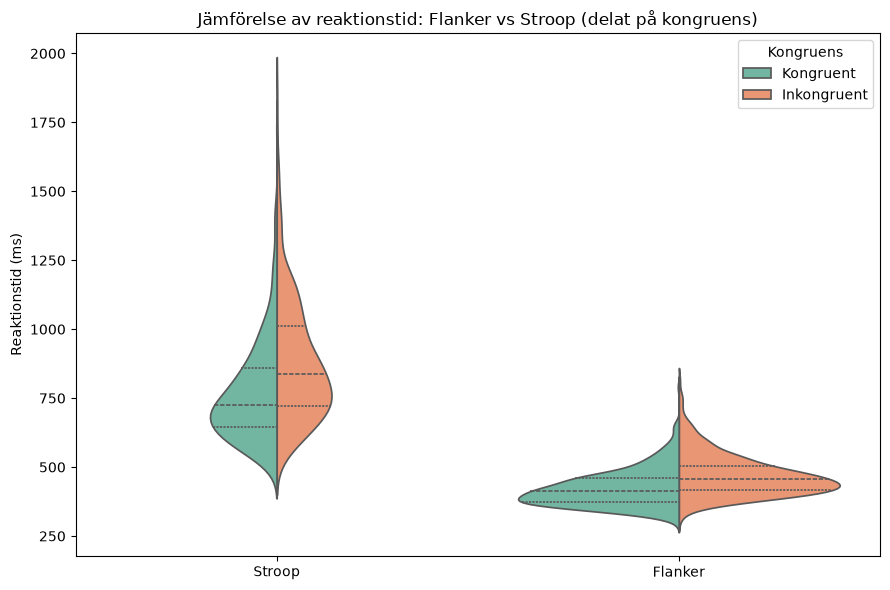

Median reaktionstid (ms), korrekta svar
         Kongruent  Inkongruent
Stroop         726          836
Flanker        413          456


In [52]:
# Violin plot
# Fördelningen av medelreaktionstider i varje test och betingelse. 

plt.figure(figsize=(9, 6))
sns.violinplot(data=df_long, x='Test', y='Latency (ms)', hue='congruence',
              hue_order=['Kongruent', 'Inkongruent'],
               split=True, inner='quartile', palette='Set2')
plt.title('Jämförelse av reaktionstid: Flanker vs Stroop (delat på kongruens)')
plt.xlabel('')
plt.ylabel('Reaktionstid (ms)')
plt.legend(title='Kongruens')
plt.tight_layout()
plt.show()

# medianer per test och kongruens
medianer = df_long.groupby(['Test', 'congruence'])['Latency (ms)'].median()

tabell = (medianer.unstack()
          [['Kongruent', 'Inkongruent']]            # kongruent före inkongruent
          .reindex(['Stroop', 'Flanker'])           # samma ordning som i figuren
          .round(0)
          .astype(int))
tabell.index.name = None
tabell.columns.name = None

print("Median reaktionstid (ms), korrekta svar")
print(tabell)

## Finns det ett samband mellan effekterna?:
### Har personer med stor stroop effekt också stor flanker effekt?


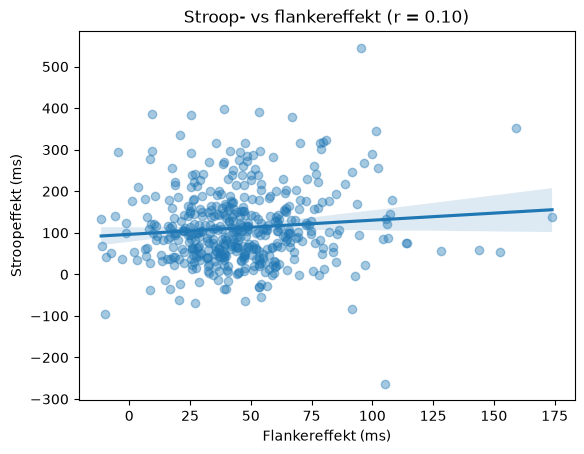

In [54]:
# Spridningsdiagram
#Finns det ett samband mellan en persons Stroop effekt och Flankereffekt? 
r = df_scatter['Stroop'].corr(df_scatter['Flanker'])

sns.regplot(data=df_scatter, x='Flanker', y='Stroop', scatter_kws={'alpha': 0.4})
plt.title(f'Stroop- vs flankereffekt (r = {r:.2f})')
plt.xlabel('Flankereffekt (ms)'); plt.ylabel('Stroopeffekt (ms)')
plt.show()

## Statistisk analys


In [56]:
#skapa en csv fil som vi kan köra in JASP

# pivotera datan och behåll full kontroll över kolumnordningen
df_anova = df_final.pivot_table(
    index='subjectid', 
    columns='congruence', 
    values=['stroop_latency', 'flanker_latency']
)

# ordna om kolumnerna så att vi vet exakt var de hamnar:
# (congruence, 1 = kongruent, 2 = inkongruent)
df_anova = df_anova[[
    ('stroop_latency', 1), 
    ('stroop_latency', 2), 
    ('flanker_latency', 1), 
    ('flanker_latency', 2)
]]

# ge kolumnerna enkla och tydliga namn
df_anova.columns = [
    'stroop_cong', 
    'stroop_incong', 
    'flanker_cong', 
    'flanker_incong'
]

df_anova = df_anova.reset_index().dropna()

# 4. Spara till CSV för JASP
df_anova.to_csv("df_anova.csv", index=False)


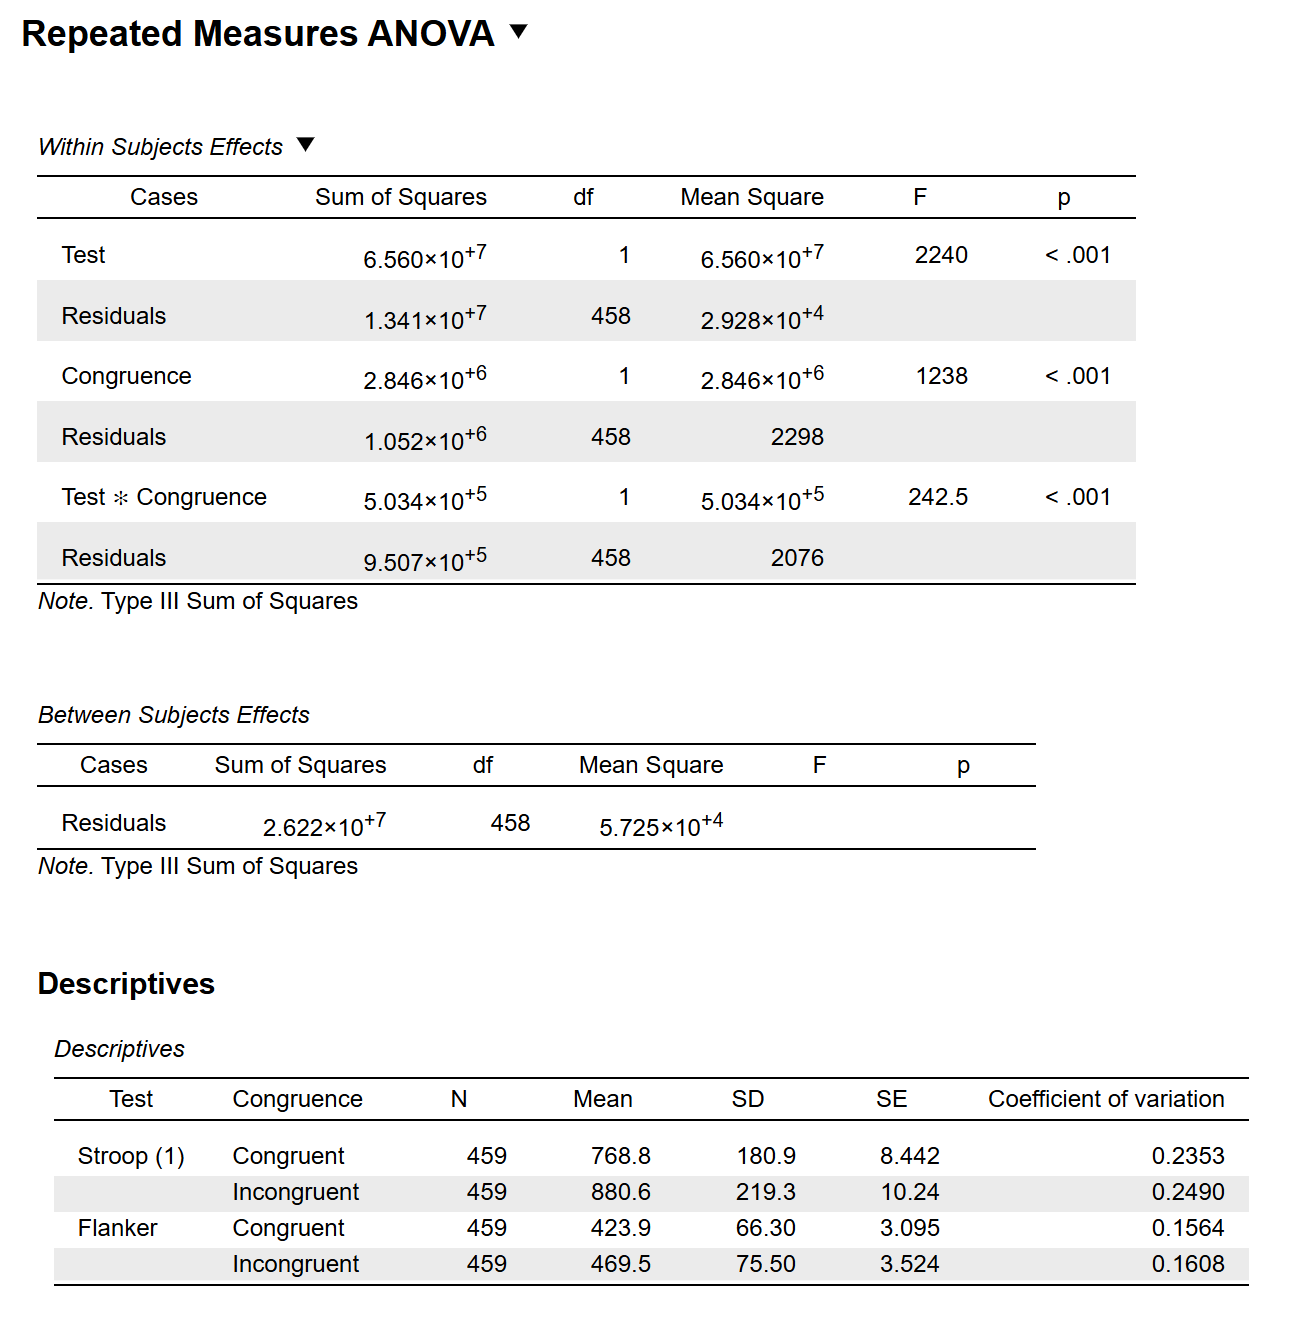

In [57]:
#lägga in skärmdump från JASP

from IPython.display import Image

Image(filename='anovapic.png', width=500)

In [58]:
# Pearson korrelation: stroop effekt och flanker effekt

from scipy.stats import pearsonr

r, p = pearsonr(df_scatter['Stroop'], df_scatter['Flanker'])

print(f"Pearson r: {r:.2f}")
print(f"p-värde: {p:.4f}")

Pearson r: 0.10
p-värde: 0.0385
